# NYC Housing & Transportation Analytics Explorer
## Data Engineering — Milestone 1

**Project focus:** Integrating NYC construction permit activity with motor-vehicle collision records to explore geographic and temporal patterns across ZIP codes and years.

### Team members

| No. | Team member | Student ID |
|---:|---|---:|
| 1 | Adham Wael | 16005914 |
| 2 | Habiba Ahmed | 16010159 |
| 3 | Youssef Khaled | 16007290 |
| 4 | Eyad Elmoataz | 16007389 |
| 5 | Hamza Feras | 16002652 |

---

In [1]:
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Load saved datasets
folder = '/content/drive/MyDrive/Data Engineering Milestone 1/Data'

df_h = pd.read_csv(f'{folder}/housing_raw.csv')
df_t = pd.read_csv(f'{folder}/transportation_raw.csv')

print("Housing dataset:", df_h.shape)
print("Transportation dataset:", df_t.shape)

Mounted at /content/drive


/tmp/ipykernel_4192/3129015869.py:10: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df_h = pd.read_csv(f'{folder}/housing_raw.csv')


Housing dataset: (50000, 46)
Transportation dataset: (33347, 29)


## 1. Dataset Overview, Sources & Selection Rationale

This project combines two NYC Open Data datasets. The downloaded extracts used in this notebook contain **50,000 housing records with 46 columns** and **33,347 transportation records with 29 columns**. The transportation API metadata may expose additional fields beyond those present in the downloaded extract; the analysis uses fields actually available in `transportation_raw.csv`.

### Housing & Development dataset — DOB NOW: Build Approved Permits

- **Dataset ID:** `rbx6-tga4`
- **Source:** [NYC Open Data — DOB NOW: Build Approved Permits](https://data.cityofnewyork.us/resource/rbx6-tga4.csv)
- **Downloaded extract:** 50,000 rows × 46 columns.
- **Selected geographic attribute:** `zip_code`
- **Selected temporal attribute:** `approved_date` (converted to year).
- **Selected category:** `work_type`
- **Measure after aggregation:** `permit_count`
- **Why selected:** Approved permit records provide a measurable indicator of construction activity and include geographic, temporal, and work-type attributes.

### Transportation dataset — Motor Vehicle Collisions

- **Dataset ID:** `h9gi-nx95`
- **Source:** [NYC Open Data — Motor Vehicle Collisions](https://data.cityofnewyork.us/resource/h9gi-nx95.csv)
- **Downloaded extract:** 33,347 rows × 29 columns.
- **Selected geographic attribute:** `zip_code`
- **Selected temporal attribute:** `crash_date` (converted to year).
- **Selected category:** `contributing_factor_vehicle_1`
- **Measure after aggregation:** `crash_count`
- **Why selected:** Collision records provide an indicator of road-safety incidents and include location, date, and contributing-factor information.

### Key fields used

| Purpose | Housing field | Transportation field |
|---|---|---|
| Geographic integration | `zip_code` | `zip_code` |
| Temporal integration | `approved_date` → year | `crash_date` → year |
| Category analysis | `work_type` | `contributing_factor_vehicle_1` |
| Unique event identifier | `job_filing_number` | `collision_id` |
| Borough context | `borough` | `borough` |

The two sources were selected because they share a usable geographic key and can be transformed to a common annual time level. The analysis explores associations and patterns; it does **not** establish that construction activity causes traffic collisions.

## 2. Analysis Workflow

The notebook follows this sequence:

1. Load the downloaded source extracts from the project Google Drive folder.
2. Inspect source metadata and confirm the fields used in the analysis.
3. Explore the raw datasets with descriptive statistics and borough distributions.
4. Clean each dataset independently before integration.
5. Aggregate both sources to **ZIP code + year**.
6. Integrate the aggregated tables using an outer join.
7. Apply post-integration cleaning and validate join coverage.
8. Create ten visualizations to investigate the research questions.
9. Export the integrated and category-level datasets for the Dash website.

**Reproducibility note:** The first loading cell expects `housing_raw.csv` and `transportation_raw.csv` in `MyDrive/Data Engineering Milestone 1/Data`. Keep those filenames and folder path unchanged, or update the path in that cell before running the notebook.

In [2]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlencode

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

HOUSING_ID = "rbx6-tga4"          # DOB NOW: Build – Approved Permits
TRANSPORT_ID = "h9gi-nx95"        # Motor Vehicle Collisions

print("Housing dataset ID:", HOUSING_ID)
print("Transport dataset ID:", TRANSPORT_ID)

Housing dataset ID: rbx6-tga4
Transport dataset ID: h9gi-nx95


## 1. Dataset Overview & Selection Rationale

We selected two core datasets from NYC Open Data to investigate the intersection of urban development and public safety:
1. **Housing Dataset (H3): DOB NOW: Build Approved Permits** (Dataset ID: `rbx6-tga4`)[cite: 8, 9]
   * **Attributes:** Contains event-level construction permit filings, including filing numbers, work types, borough, ZIP codes, and approval dates[cite: 10].
   * **Reasoning:** Tracks where private and commercial investment is actively reshaping neighborhoods.
2. **Transportation Dataset (T4): Motor Vehicle Collisions** (Dataset ID: `h9gi-nx95`)[cite: 8, 9]
   * **Attributes:** Records citywide traffic crash incidents, including collision IDs, crash dates, times, borough, and ZIP codes.
   * **Reasoning:** Measures roadway safety friction and traffic incidents.
   * **Integration Rationale:** By aggregating both datasets to a common geographic (ZIP code / Borough) and temporal (Year) granularity, we can analyze whether areas undergoing heavy building permit activity experience corresponding shifts in motor vehicle collisions.

In [3]:
# ============================================================
# CELL 2 — Inspect the real API column names before loading
# ============================================================
def get_columns(dataset_id):
    """Return a DataFrame of fieldName and dataTypeName from Socrata metadata."""
    url = f"https://data.cityofnewyork.us/api/views/{dataset_id}/columns.json"
    return pd.read_json(url)[["fieldName", "dataTypeName", "name"]]

h_cols = get_columns(HOUSING_ID)
t_cols = get_columns(TRANSPORT_ID)

print("H3 columns:", len(h_cols))
display(h_cols)

print("\nT4 columns:", len(t_cols))
display(t_cols)

H3 columns: 46


,fieldName,dataTypeName,name
0,job_filing_number,text,Job Filing Number
1,work_permit,text,Work Permit
2,sequence_number,text,Sequence Number
3,filing_reason,text,Filing Reason
4,house_no,text,House No
5,street_name,text,Street Name
6,borough,text,Borough
7,lot,text,LOT
8,bin,text,Bin
9,block,text,Block



T4 columns: 33


,fieldName,dataTypeName,name
0,crash_date,calendar_date,CRASH DATE
1,crash_time,text,CRASH TIME
2,borough,text,BOROUGH
3,zip_code,text,ZIP CODE
4,latitude,number,LATITUDE
5,longitude,number,LONGITUDE
6,location,point,LOCATION
7,on_street_name,text,ON STREET NAME
8,location_address,text,LOCATION (address)
9,off_street_name,text,CROSS STREET NAME


In [4]:
# ============================================================
# CELL 5 — Define the final integration key
# ============================================================
# Both H3 and T4 expose zip_code, so ZIP Code + Year is the
# final integration level used throughout the notebook.
JOIN_KEY = "zip_code"

if JOIN_KEY not in df_h.columns or JOIN_KEY not in df_t.columns:
    raise KeyError("ZIP code is required in both datasets for the final integration.")

print("Final integration key: ZIP Code + Year")
print("H3 has zip_code:", JOIN_KEY in df_h.columns)
print("T4 has zip_code:", JOIN_KEY in df_t.columns)


Final integration key: ZIP Code + Year
H3 has zip_code: True
T4 has zip_code: True


=== HOUSING DATASET (H3) EDA ===
Shape: (50000, 46)


,job_filing_number,work_permit,sequence_number,filing_reason,house_no,street_name,borough,lot,bin,block,c_b_no,apt_condo_no_s,work_on_floor,work_type,permittee_s_license_type,applicant_license,applicant_first_name,applicant_middle_name,applicant_last_name,applicant_business_name,applicant_business_address,filing_representative_first_name,filing_representative_middle_initial,filing_representative_last_name,filing_representative_business_name,approved_date,issued_date,expired_date,job_description,estimated_job_costs,owner_business_name,owner_name,owner_street_address,owner_city,owner_state,owner_zip_code,permit_status,tracking_number,zip_code,latitude,longitude,community_board,council_district,bbl,census_tract,nta
count,49991,49991,49943.0,49964,50000,50000,50000,49999.0,50000.0,50000.0,49573.0,25,48163,50000,50000,50000,49991,8305,50000,49871,49480,26445,1037,26431,26191,49998,49943,49931,50000,50000.0,47267,48971,0.0,0.0,0.0,0.0,50000,50000.0,49924.0,49794.0,49794.0,49794.0,49794.0,48646.0,49794.0,49794
unique,34096,35049,NaN,4,7114,4012,10,NaN,NaN,NaN,NaN,4,5043,21,9,6686,2651,29,4482,6199,6225,1199,30,1480,1473,2580,2323,4118,26376,NaN,7036,14107,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,224
top,Permit is no,Permit is not yet issued,NaN,Initial Permit,1,BROADWAY,MANHATTAN,NaN,NaN,NaN,NaN,OSP,Open Space,General Construction,GC,623088,MICHAEL,J,SINGH,ANDAMIO SCAFFOLDING LLC,20 BURLING LANE (BOX 4-1),ELY,M,SEPULVEDA,AE DESIGN SOLUTION INC.,2026-07-28T00:00:00.000,2026-09-10T00:00:00.000,2026-12-31T00:00:00.000,INSTALLATION OF TEMPORARY HEAVY DUTY SIDEWALK ...,NaN,PR,CHARLESTON ALBERT,NaN,NaN,NaN,NaN,Signed-off,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Midtown-Times Square
freq,59,59,NaN,32902,418,1108,12271,NaN,NaN,NaN,NaN,21,7912,11363,36909,682,1463,1453,2366,692,616,917,153,952,927,100,533,572,583,NaN,9479,446,NaN,NaN,NaN,NaN,26625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2591


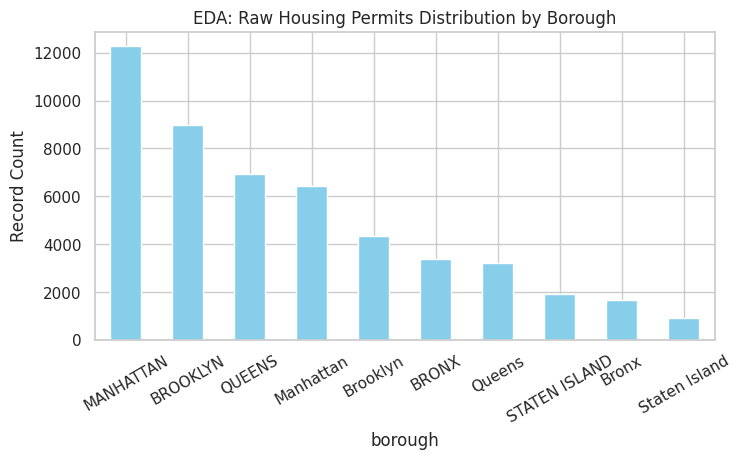


=== TRANSPORT DATASET (T4) EDA ===
Shape: (33347, 29)


,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,contributing_factor_vehicle_1,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
count,33347,33347,25415,24250.0,31480.0,31480.0,31480,24190,9157,17893,33347.0,33347.0,33347.0,33347.0,33347.0,33347.0,33347.0,33347.0,30265,18998,2173,608,170,33347,23785,16252,2009,573,159
unique,2491,1440,5,NaN,NaN,NaN,24493,4382,8806,4887,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61,48,26,14,11,33347,168,192,40,25,10
top,2020-03-06,00:00,BROOKLYN,NaN,NaN,NaN,"\n, \n(40.74947, -73.7564)",BELT PARKWAY,772 EDGEWATER ROAD,BROADWAY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Driver Inattention/Distraction,Unspecified,Unspecified,Unspecified,Unspecified,98ca2cc497d18d811ae7b45af6b2879e,Sedan,Sedan,Sedan,Sedan,Sedan
freq,35,575,8722,NaN,NaN,NaN,16,356,7,210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7195,12946,1679,489,136,1,10605,6196,923,266,83


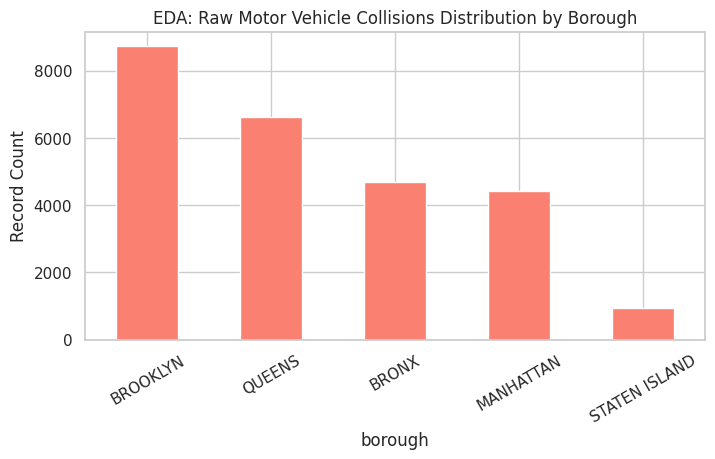

In [5]:
# Exploratory Data Analysis (EDA) on Raw Datasets
print("=== HOUSING DATASET (H3) EDA ===")
print("Shape:", df_h.shape)
display(df_h.describe(include='all').head(4))

# Quick distribution plot of permits by borough if column exists
if 'borough' in df_h.columns:
    plt.figure(figsize=(8, 4))
    df_h['borough'].value_counts().plot(kind='bar', color='skyblue')
    plt.title("EDA: Raw Housing Permits Distribution by Borough")
    plt.ylabel("Record Count")
    plt.xticks(rotation=30)
    plt.show()

print("\n=== TRANSPORT DATASET (T4) EDA ===")
print("Shape:", df_t.shape)
display(df_t.describe(include='all').head(4))

if 'borough' in df_t.columns:
    plt.figure(figsize=(8, 4))
    df_t['borough'].value_counts().plot(kind='bar', color='salmon')
    plt.title("EDA: Raw Motor Vehicle Collisions Distribution by Borough")
    plt.ylabel("Record Count")
    plt.xticks(rotation=30)
    plt.show()

In [6]:
# CELL 6 Pre-integration cleaning: H3 (Updated with Outlier Detection)
def clean_housing(df, join_key):
    df = df.copy()

    # --- Borough standardisation ---
    if "borough" in df.columns:
        df["borough"] = (
            df["borough"]
            .astype(str)
            .str.strip()
            .str.upper()
            .replace({"STATEN ISLAND": "STATEN ISLAND", "STATED ISLAND": "STATEN ISLAND"})
        )

    # --- ZIP cleaning (only if the column exists) ---
    if "zip_code" in df.columns:
        df["zip_code"] = (
            df["zip_code"]
            .astype(str)
            .str.replace(r"\.0$", "", regex=True)
            .str.zfill(5)
        )
        valid_zips = df["zip_code"].str.match(r"^1(0[0-4]|1[0-4]|16)\d{2}$")
        print(f"H3: dropping {(~valid_zips & df['zip_code'].notna()).sum()} invalid ZIPs")
        df = df[valid_zips | df["zip_code"].isna()]

    # --- Outlier Detection & Handling (IQR Method on estimated job costs) ---
    if "estimated_job_costs" in df.columns:
        df["estimated_job_costs"] = pd.to_numeric(df["estimated_job_costs"], errors="coerce")
        Q1 = df["estimated_job_costs"].quantile(0.25)
        Q3 = df["estimated_job_costs"].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        initial_count = len(df)
        df = df[(df["estimated_job_costs"].isna()) | ((df["estimated_job_costs"] >= lower_bound) & (df["estimated_job_costs"] <= upper_bound))]
        print(f"H3: Removed {initial_count - len(df)} extreme outlier rows based on estimated job costs.")

    # --- Drop rows with no borough ---
    before = len(df)
    df = df.dropna(subset=["borough"])
    print(f"H3: dropped {before - len(df)} rows with null borough")

    # --- Drop exact duplicates on job filing number ---
    if "job_filing_number" in df.columns:
        before = len(df)
        df = df.drop_duplicates(subset=["job_filing_number"])
        print(f"H3: removed {before - len(df)} duplicate filings")

    # --- Date field: use Approved Date for the analysis year ---
    # The API inspection above confirms that H3 contains approved_date.
    if "approved_date" in df.columns:
        chosen = "approved_date"
        print(f"H3: using '{chosen}' as the date field")
        df["year"] = pd.to_datetime(df[chosen], errors="coerce").dt.year
    else:
        raise KeyError("H3 approved_date column was not found. Check the live API columns before continuing.")

    return df

df_h_clean = clean_housing(df_h, JOIN_KEY)
print("H3 cleaned shape:", df_h_clean.shape)

H3: dropping 85 invalid ZIPs
H3: Removed 7485 extreme outlier rows based on estimated job costs.
H3: dropped 0 rows with null borough
H3: removed 12210 duplicate filings
H3: using 'approved_date' as the date field
H3 cleaned shape: (30220, 47)


In [7]:
# CELL 7 Pre-integration cleaning: T4 (Updated with Outlier Detection)
def clean_transport(df, join_key):
    df = df.copy()

    # --- Borough standardisation ---
    if "borough" in df.columns:
        df["borough"] = (
            df["borough"]
            .astype(str)
            .str.strip()
            .str.upper()
        )

    # --- ZIP cleaning ---
    if "zip_code" in df.columns:
        df["zip_code"] = (
            df["zip_code"]
            .astype(str)
            .str.replace(r"\.0$", "", regex=True)
            .str.zfill(5)
        )
        valid_zips = df["zip_code"].str.match(r"^1(0[0-4]|1[0-4]|16)\d{2}$")
        print(f"T4: dropping {(~valid_zips & df['zip_code'].notna()).sum()} invalid ZIPs")
        df = df[valid_zips | df["zip_code"].isna()]

    # --- Outlier Detection & Handling (Domain Rules for NYC Coordinates) ---
    if "latitude" in df.columns and "longitude" in df.columns:
        df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
        df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

        # Valid bounding box for New York City geographic coordinates
        nyc_lat_bounds = (40.45, 40.92)
        nyc_lon_bounds = (-74.26, -73.70)

        initial_count = len(df)
        valid_coords = (
            (df["latitude"].isna()) | ((df["latitude"] >= nyc_lat_bounds[0]) & (df["latitude"] <= nyc_lat_bounds[1]))
        ) & (
            (df["longitude"].isna()) | ((df["longitude"] >= nyc_lon_bounds[0]) & (df["longitude"] <= nyc_lon_bounds[1]))
        )
        df = df[valid_coords]
        print(f"T4: Removed {initial_count - len(df)} records with out-of-bounds geographic coordinates.")

    # --- Drop rows with no borough ---
    before = len(df)
    df = df.dropna(subset=["borough"])
    print(f"T4: dropped {before - len(df)} rows with null borough")

    # --- Parse crash date and extract year ---
    if "crash_date" in df.columns:
        df["crash_date"] = pd.to_datetime(df["crash_date"], errors="coerce")
        df["year"] = df["crash_date"].dt.year
        before = len(df)
        df = df.dropna(subset=["year"])
        print(f"T4: dropped {before - len(df)} rows with unparseable crash_date")

    # --- Remove duplicate crash records ---
    if "collision_id" in df.columns:
        before = len(df)
        df = df.drop_duplicates(subset=["collision_id"])
        print(f"T4: removed {before - len(df)} duplicate collisions")

    return df

df_t_clean = clean_transport(df_t, JOIN_KEY)
print("T4 cleaned shape:", df_t_clean.shape)

T4: dropping 9097 invalid ZIPs
T4: Removed 0 records with out-of-bounds geographic coordinates.
T4: dropped 0 rows with null borough
T4: dropped 0 rows with unparseable crash_date
T4: removed 0 duplicate collisions
T4 cleaned shape: (24250, 30)


In [8]:
import pandas as pd

# ============================================================
# CELL 8 — Aggregate both datasets to ZIP Code + Year
# ============================================================
def aggregate_housing(df, key):
    """Count approved permits per ZIP code and year (as datetime)."""
    agg = (
        df.groupby([key, "year"])
        .size()
        .reset_index(name="permit_count")
    )
    # Convert year to datetime (e.g. YYYY-01-01)
    agg["year"] = pd.to_datetime(agg["year"].astype(int).astype(str) + "-01-01", errors="coerce")
    return agg

def aggregate_transport(df, key):
    """Count motor vehicle collisions per ZIP code and year (as datetime)."""
    agg = (
        df.groupby([key, "year"])
        .size()
        .reset_index(name="crash_count")
    )
    # Convert year to datetime to maintain consistency with housing
    agg["year"] = pd.to_datetime(agg["year"].astype(int).astype(str) + "-01-01", errors="coerce")
    return agg

# Both datasets are transformed to the same ZIP Code + Year (Date type) granularity.
h_agg = aggregate_housing(df_h_clean, JOIN_KEY)
t_agg = aggregate_transport(df_t_clean, JOIN_KEY)

print("Housing aggregation shape:", h_agg.shape)
display(h_agg.head())

print("\nTransport aggregation shape:", t_agg.shape)
display(t_agg.head())

Housing aggregation shape: (1681, 3)


,zip_code,year,permit_count
0,10000,2022-01-01,2
1,10000,2023-01-01,1
2,10000,2024-01-01,1
3,10001,2017-01-01,1
4,10001,2018-01-01,17



Transport aggregation shape: (1252, 3)


,zip_code,year,crash_count
0,10000,2021-01-01,2
1,10000,2022-01-01,2
2,10000,2023-01-01,2
3,10000,2025-01-01,1
4,10000,2026-01-01,1


In [9]:
# ============================================================
# CELL 9 — Integrate (merge) and post-integration cleaning
# ============================================================
# Merge the two aggregated datasets using the final common granularity:
# ZIP Code + Year.
merged = pd.merge(
    h_agg,
    t_agg,
    on=[JOIN_KEY, "year"],
    how="outer",
    indicator=True
)

# Post-integration cleaning
merged["permit_count"] = merged["permit_count"].fillna(0).astype(int)
merged["crash_count"] = merged["crash_count"].fillna(0).astype(int)

# Drop rows where both sides are zero (uninformative cells).
before = len(merged)
merged = merged[(merged["permit_count"] > 0) | (merged["crash_count"] > 0)]
print(f"Post-join: dropped {before - len(merged)} empty cells")

both = (merged["_merge"] == "both").sum()
print(f"Cells with both signals: {both} ({both/len(merged)*100:.1f}%)")
print(merged["_merge"].value_counts())

df_int = merged.drop(columns=["_merge"])
print("\nIntegrated shape:", df_int.shape)
display(df_int.head(10))


Post-join: dropped 0 empty cells
Cells with both signals: 1186 (67.9%)
_merge
both          1186
left_only      495
right_only      66
Name: count, dtype: int64

Integrated shape: (1747, 4)


,zip_code,year,permit_count,crash_count
0,10000,2021-01-01,0,2
1,10000,2022-01-01,2,2
2,10000,2023-01-01,1,2
3,10000,2024-01-01,1,0
4,10000,2025-01-01,0,1
5,10000,2026-01-01,0,1
6,10001,2017-01-01,1,0
7,10001,2018-01-01,17,0
8,10001,2019-01-01,29,0
9,10001,2020-01-01,26,17


## 3. Research Questions & Visualization Plan

The ten questions below are answered by the ten visualizations in this notebook.

| Visualization | Research question |
|---:|---|
| 1 | How do total approved building permits and motor-vehicle collisions compare across NYC boroughs? |
| 2 | Across borough-year observations, how are permit counts associated with collision counts? |
| 3 | Which ZIP codes have the highest total number of approved building permits? |
| 4 | Which ZIP codes have the highest total number of motor-vehicle collisions? |
| 5 | How has approved building permit activity changed over the years covered by the data? |
| 6 | How have motor-vehicle collision counts changed over the years covered by the data? |
| 7 | Across years, how do average ZIP-level permit counts relate to average ZIP-level collision counts? |
| 8 | How is building permit activity distributed across the highest-activity ZIP codes over time? |
| 9 | How is collision activity distributed across the highest-activity ZIP codes over time? |
| 10 | Across ZIP codes, what relationship is visible between total approved permits and total motor-vehicle collisions? |

### Proposed analysis ownership (confirm against actual team contributions)

The following is a suggested way to distribute the ten questions and visualizations evenly. Adjust it if the actual work split was different; do not present this proposal as a record of completed individual contributions unless the team confirms it.

| Team member | Suggested questions / visualizations |
|---|---|
| Adham Wael | 1 and 2 |
| Habiba Ahmed | 3 and 4 |
| Youssef Khaled | 5 and 6 |
| Eyad Elmoataz | 7 and 8 |
| Hamza Feras | 9 and 10 |

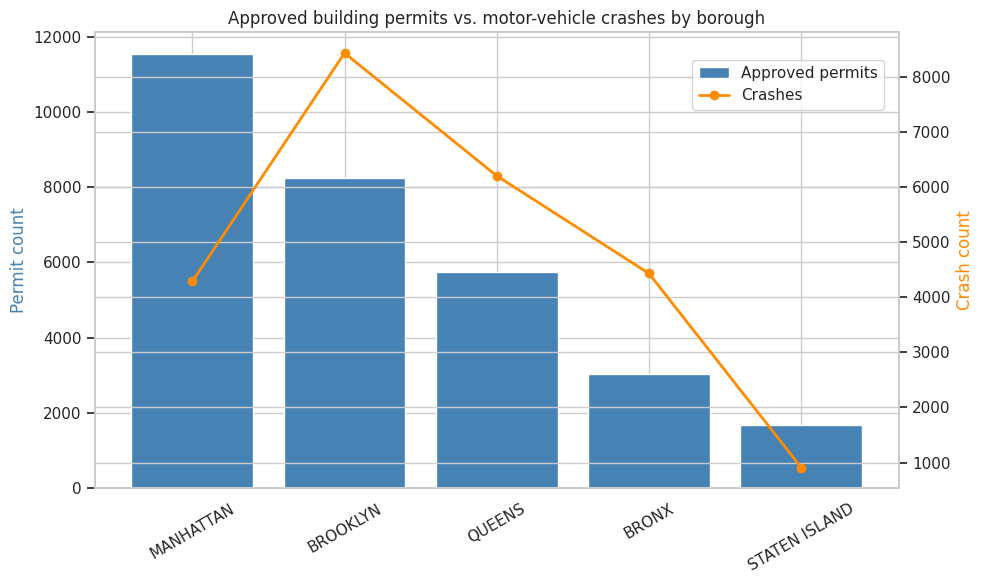

In [10]:
# ============================================================
# CELL 10 — Visualisation 1: Permits vs crashes by borough
# ============================================================
# The integration is performed at ZIP + Year. For this citywide
# comparison, map each integrated ZIP code to its borough.
zip_to_borough = {}
for df in [df_h_clean, df_t_clean]:
    if "zip_code" in df.columns and "borough" in df.columns:
        mapping = (
            df.dropna(subset=["zip_code", "borough"])
            .drop_duplicates(subset=["zip_code"])
            .set_index("zip_code")["borough"]
            .to_dict()
        )
        zip_to_borough.update(mapping)

df_int["borough"] = df_int["zip_code"].map(zip_to_borough)

borough_compare = (
    df_int.dropna(subset=["borough"])
    .groupby("borough")[["permit_count", "crash_count"]]
    .sum()
    .sort_values("permit_count", ascending=False)
)

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(
    borough_compare.index,
    borough_compare["permit_count"],
    color="steelblue",
    label="Approved permits",
)
ax2 = ax1.twinx()
ax2.plot(
    borough_compare.index,
    borough_compare["crash_count"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Crashes",
)
ax1.set_ylabel("Permit count", color="steelblue")
ax2.set_ylabel("Crash count", color="darkorange")
ax1.set_title("Approved building permits vs. motor-vehicle crashes by borough")
ax1.tick_params(axis="x", rotation=30)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()


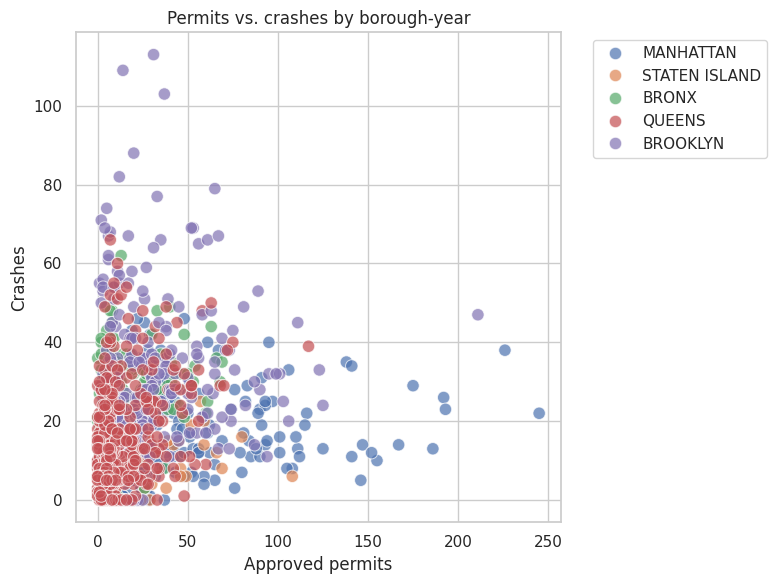

In [11]:
# ============================================================
# CELL 11 — Visualisation 2: Relationship scatter (borough-year)
# ============================================================
# Only works if a year column survived; otherwise skip gracefully.
if "year" in df_int.columns and df_int["year"].notna().any():
    scatter_data = df_int.dropna(subset=["year"])

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=scatter_data,
        x="permit_count",
        y="crash_count",
        hue="borough",
        alpha=0.7,
        s=80,
    )
    plt.title("Permits vs. crashes by borough-year")
    plt.xlabel("Approved permits")
    plt.ylabel("Crashes")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("No usable year column — scatter skipped. Falling back to borough-only view.")
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df_int,
        x="permit_count",
        y="crash_count",
        hue="borough",
        s=120,
    )
    plt.title("Permits vs. crashes by borough")
    plt.xlabel("Approved permits")
    plt.ylabel("Crashes")
    plt.tight_layout()
    plt.show()

## Integration Justification & Post-Integration Cleaning

**Final integration granularity: ZIP code + year.**

ZIP code was selected as the geographic integration attribute because both datasets contain a `zip_code` field. Year was selected as the common temporal attribute because the housing source contains `approved_date` and the transportation source contains `crash_date`.

A row-level join would not be appropriate: the sources describe different types of events, have different record counts, and do not share a common event identifier. Instead, each source is aggregated independently to ZIP code + year:

- **Housing:** count approved permit records for each ZIP-year combination.
- **Transportation:** count collision records for each ZIP-year combination.

The aggregated tables are combined using an **outer join** on ZIP code and year. This preserves ZIP-year combinations that appear in only one source instead of discarding them.

### Post-integration cleaning

- Missing `permit_count` values introduced by the outer join are filled with zero.
- Missing `crash_count` values introduced by the outer join are filled with zero.
- Both count columns are converted to integers.
- Rows where both counts are zero are removed because they contain no recorded activity from either source.
- The temporary merge indicator is removed after join-coverage validation.

### Join coverage in the current run

The current run produces **1,747 ZIP-year rows**:
- 1,186 ZIP-year combinations contain records from both sources.
- 495 combinations appear only in the housing aggregation.
- 66 combinations appear only in the transportation aggregation.

### Limitations

ZIP-year aggregation supports comparison at a shared geographic and temporal level, but it hides variation within each ZIP code and within each year. A ZIP-year association does not prove causation. Collision counts can also be influenced by traffic volume, road design, population, reporting practices, and other factors not controlled for in this analysis. Zero counts mean no matching record was present in the downloaded and cleaned extract, not necessarily that the underlying activity never occurred.

In [12]:
# ============================================================
# Export the integrated dataset for the website
# ============================================================
import os

OUTPUT_FOLDER = "/content/drive/MyDrive/Data Engineering Milestone 1/Data"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# df_int already includes borough after the borough-mapping step.
integrated_output = os.path.join(OUTPUT_FOLDER, "integrated_data.csv")
df_int.to_csv(integrated_output, index=False)

print("Integrated dataset exported successfully.")
print("Shape:", df_int.shape)
print("File:", integrated_output)

Integrated dataset exported successfully.
Shape: (1747, 5)
File: /content/drive/MyDrive/Data Engineering Milestone 1/Data/integrated_data.csv


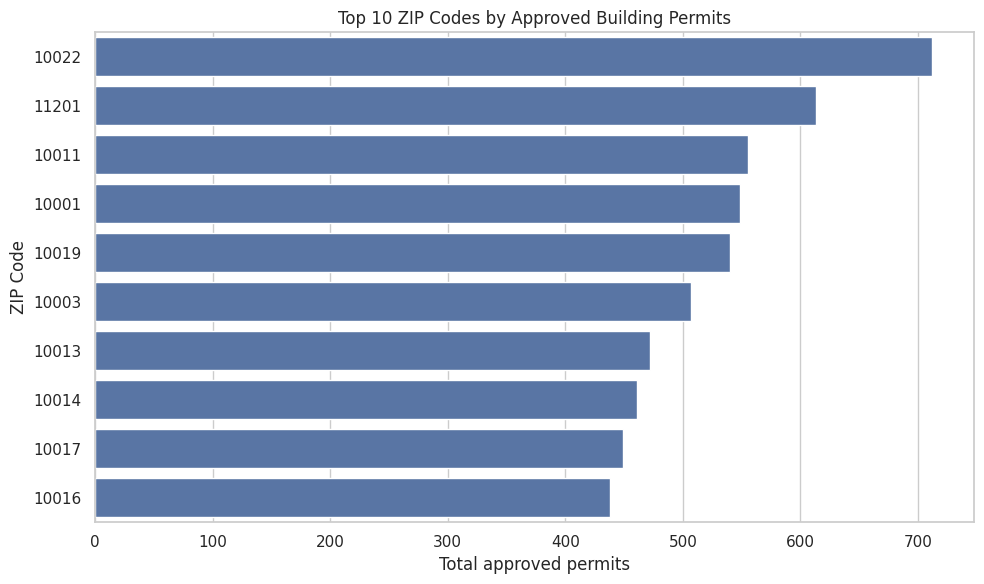

In [13]:
# ============================================================
# CELL 14 — Visualization 3: Top ZIP Codes by Approved Permits
# ============================================================

top_permit_zips = (
    df_int.groupby("zip_code", as_index=False)["permit_count"]
          .sum()
          .sort_values("permit_count", ascending=False)
          .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_permit_zips,
    x="permit_count",
    y="zip_code"
)

plt.title("Top 10 ZIP Codes by Approved Building Permits")
plt.xlabel("Total approved permits")
plt.ylabel("ZIP Code")
plt.tight_layout()
plt.show()

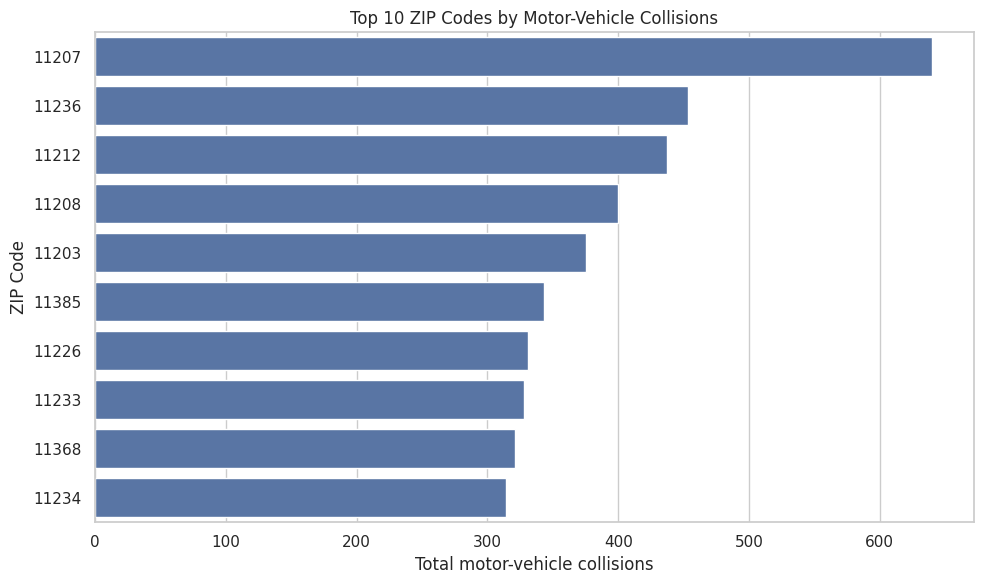

In [14]:
# ============================================================
# CELL 15 — Visualization 4: Top ZIP Codes by Collisions
# ============================================================

top_crash_zips = (
    df_int.groupby("zip_code", as_index=False)["crash_count"]
          .sum()
          .sort_values("crash_count", ascending=False)
          .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_crash_zips,
    x="crash_count",
    y="zip_code"
)

plt.title("Top 10 ZIP Codes by Motor-Vehicle Collisions")
plt.xlabel("Total motor-vehicle collisions")
plt.ylabel("ZIP Code")
plt.tight_layout()
plt.show()

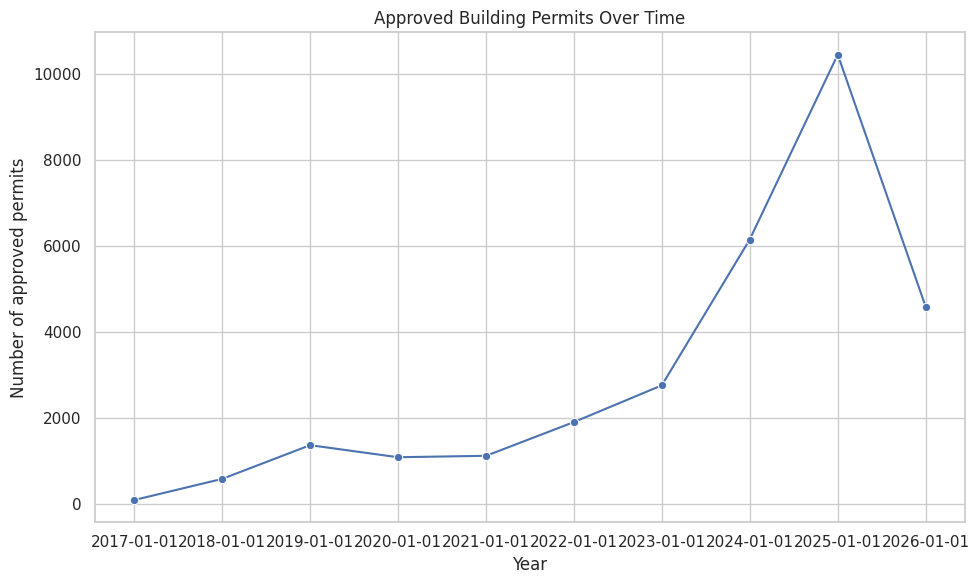

In [15]:
# ============================================================
# CELL 16 — Visualization 5: Building Permits Over Time
# ============================================================

permit_yearly = (
    df_int.groupby("year", as_index=False)["permit_count"]
          .sum()
          .sort_values("year")
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=permit_yearly,
    x="year",
    y="permit_count",
    marker="o"
)

plt.title("Approved Building Permits Over Time")
plt.xlabel("Year")
plt.ylabel("Number of approved permits")
plt.xticks(permit_yearly["year"])
plt.tight_layout()
plt.show()

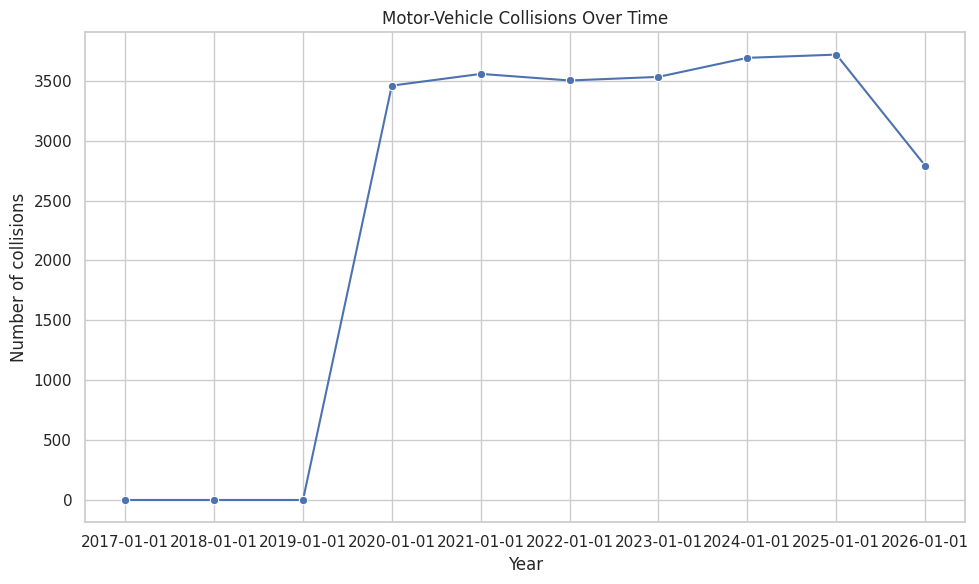

In [16]:
# ============================================================
# CELL 17 — Visualization 6: Collisions Over Time
# ============================================================

crash_yearly = (
    df_int.groupby("year", as_index=False)["crash_count"]
          .sum()
          .sort_values("year")
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=crash_yearly,
    x="year",
    y="crash_count",
    marker="o"
)

plt.title("Motor-Vehicle Collisions Over Time")
plt.xlabel("Year")
plt.ylabel("Number of collisions")
plt.xticks(crash_yearly["year"])
plt.tight_layout()
plt.show()

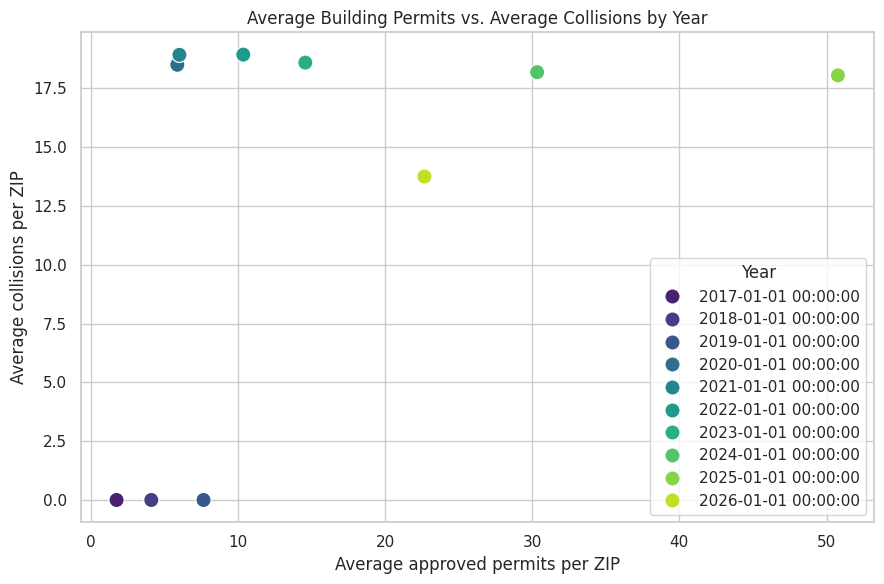

In [17]:
# ============================================================
# CELL 18 — Visualization 7: Average Permits vs. Average Collisions
# ============================================================

year_avg = (
    df_int.groupby("year", as_index=False)[
        ["permit_count", "crash_count"]
    ]
    .mean()
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=year_avg,
    x="permit_count",
    y="crash_count",
    hue="year",
    palette="viridis",
    s=120
)

plt.title("Average Building Permits vs. Average Collisions by Year")
plt.xlabel("Average approved permits per ZIP")
plt.ylabel("Average collisions per ZIP")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

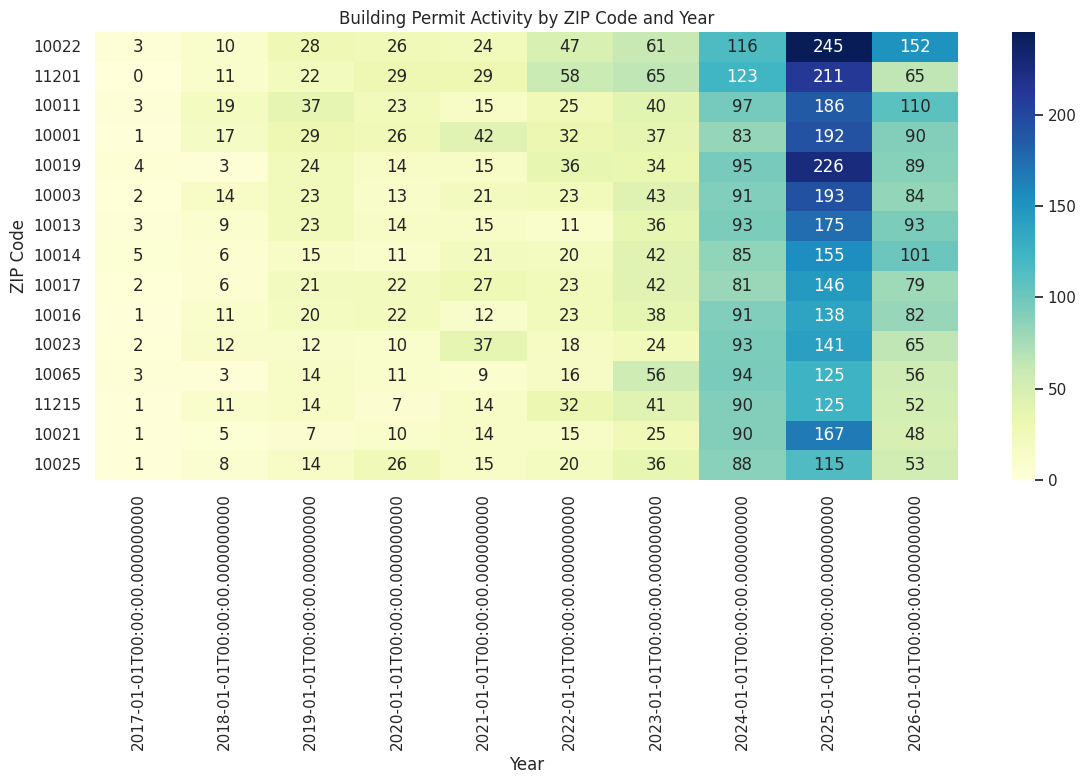

In [18]:
# ============================================================
# CELL 19 — Visualization 8: Building Activity Heatmap
# ============================================================

permit_heatmap = (
    df_int.pivot_table(
        index="zip_code",
        columns="year",
        values="permit_count",
        aggfunc="sum",
        fill_value=0
    )
)

# Keep the ZIP codes with the highest total permit activity
top_heatmap_zips = (
    permit_heatmap.sum(axis=1)
                  .sort_values(ascending=False)
                  .head(15)
                  .index
)

permit_heatmap_top = permit_heatmap.loc[top_heatmap_zips]

plt.figure(figsize=(12, 8))

sns.heatmap(
    permit_heatmap_top,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Building Permit Activity by ZIP Code and Year")
plt.xlabel("Year")
plt.ylabel("ZIP Code")
plt.tight_layout()
plt.show()

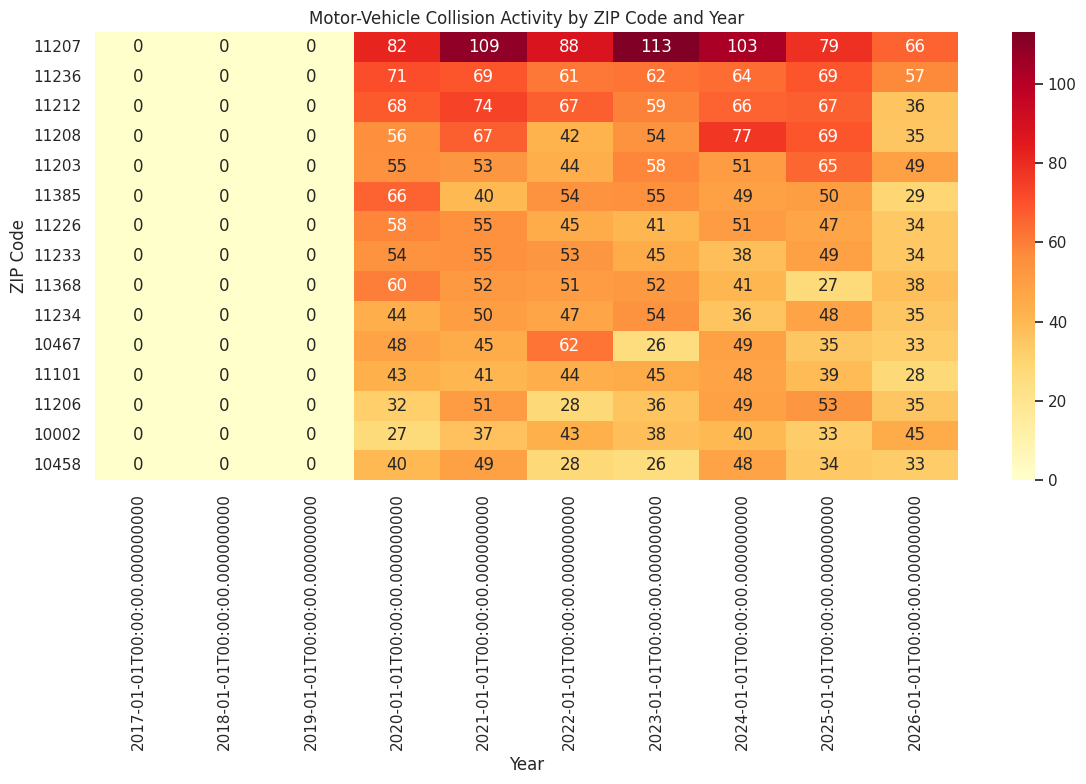

In [19]:
# ============================================================
# CELL 20 — Visualization 9: Collision Activity Heatmap
# ============================================================

crash_heatmap = (
    df_int.pivot_table(
        index="zip_code",
        columns="year",
        values="crash_count",
        aggfunc="sum",
        fill_value=0
    )
)

# Keep the ZIP codes with the highest total collision activity
top_crash_heatmap_zips = (
    crash_heatmap.sum(axis=1)
                .sort_values(ascending=False)
                .head(15)
                .index
)

crash_heatmap_top = crash_heatmap.loc[top_crash_heatmap_zips]

plt.figure(figsize=(12, 8))

sns.heatmap(
    crash_heatmap_top,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Motor-Vehicle Collision Activity by ZIP Code and Year")
plt.xlabel("Year")
plt.ylabel("ZIP Code")
plt.tight_layout()
plt.show()

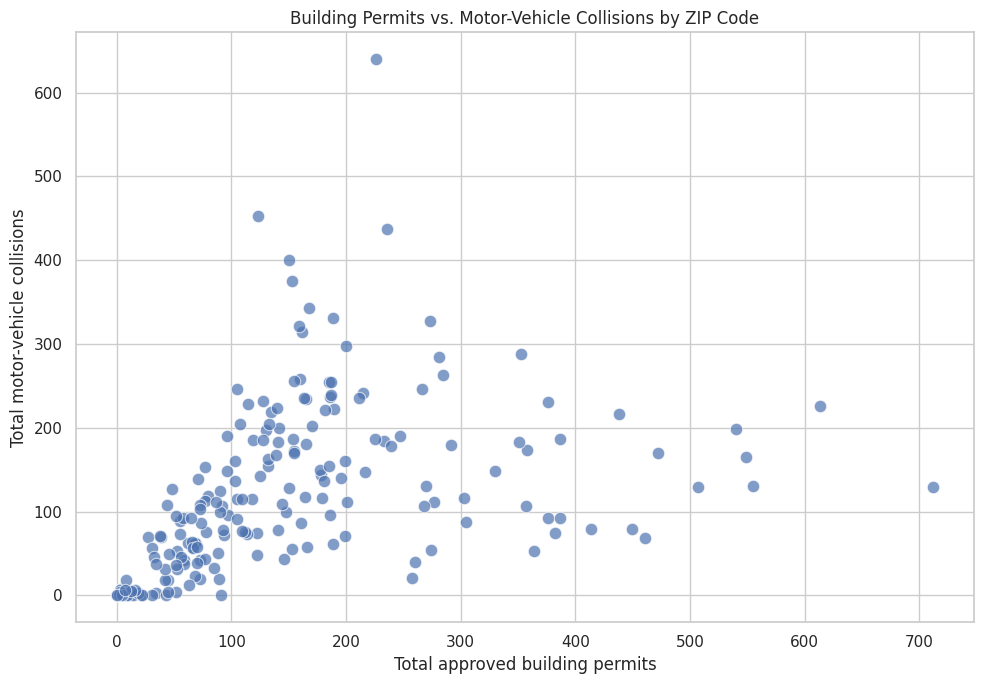

In [20]:
# ============================================================
# CELL 21 — Visualization 10: ZIP-Level Permit vs Collision Relationship
# ============================================================

zip_relationship = (
    df_int.groupby("zip_code", as_index=False)[
        ["permit_count", "crash_count"]
    ]
    .sum()
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=zip_relationship,
    x="permit_count",
    y="crash_count",
    alpha=0.7,
    s=80
)

plt.title("Building Permits vs. Motor-Vehicle Collisions by ZIP Code")
plt.xlabel("Total approved building permits")
plt.ylabel("Total motor-vehicle collisions")

plt.tight_layout()
plt.show()

## 4. Category-Level Analysis Data

In addition to the ZIP-year integrated table, two category-level datasets are created for the website filters:

- **Housing category:** `work_type`, grouped by ZIP code, year, and borough; `permit_count` is the number of unique job filing numbers.
- **Transportation category:** `contributing_factor_vehicle_1`, grouped by ZIP code, year, and borough; `collision_count` is the number of unique collision IDs.

Missing category labels are represented as `Unspecified`. These tables retain category detail that is not present in the five-column integrated summary.

In [21]:
# Inspect possible housing and transportation category columns

print("HOUSING COLUMNS:")
print(df_h.columns.tolist())

print("\nTRANSPORTATION COLUMNS:")
print(df_t.columns.tolist())

print("\nPOSSIBLE HOUSING CATEGORIES:")
for col in df_h.columns:
    if any(word in col.lower() for word in
           ["work_type", "permit_type", "job_type", "category"]):
        print(f"\n{col}")
        print(df_h[col].value_counts().head(10))

print("\nPOSSIBLE TRANSPORTATION CATEGORIES:")
for col in df_t.columns:
    if any(word in col.lower() for word in
           ["factor", "vehicle", "contributing", "category"]):
        print(f"\n{col}")
        print(df_t[col].value_counts().head(10))

HOUSING COLUMNS:
['job_filing_number', 'work_permit', 'sequence_number', 'filing_reason', 'house_no', 'street_name', 'borough', 'lot', 'bin', 'block', 'c_b_no', 'apt_condo_no_s', 'work_on_floor', 'work_type', 'permittee_s_license_type', 'applicant_license', 'applicant_first_name', 'applicant_middle_name', 'applicant_last_name', 'applicant_business_name', 'applicant_business_address', 'filing_representative_first_name', 'filing_representative_middle_initial', 'filing_representative_last_name', 'filing_representative_business_name', 'approved_date', 'issued_date', 'expired_date', 'job_description', 'estimated_job_costs', 'owner_business_name', 'owner_name', 'owner_street_address', 'owner_city', 'owner_state', 'owner_zip_code', 'permit_status', 'tracking_number', 'zip_code', 'latitude', 'longitude', 'community_board', 'council_district', 'bbl', 'census_tract', 'nta']

TRANSPORTATION COLUMNS:
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_stree

In [22]:

import pandas as pd
import os

# Google Drive project folder
folder = '/content/drive/MyDrive/Data Engineering Milestone 1/Data'
os.makedirs(folder, exist_ok=True)

# ==========================================
# 1. HOUSING CATEGORY DATA
# ==========================================

housing_categories = df_h_clean.copy()

housing_categories["work_type"] = (
    housing_categories["work_type"]
    .fillna("Unspecified")
    .astype(str)
    .str.strip()
)

housing_categories["zip_code"] = (
    housing_categories["zip_code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

housing_categories["year"] = pd.to_datetime(
    housing_categories["approved_date"],
    errors="coerce"
).dt.year

housing_categories = housing_categories.dropna(
    subset=["year", "borough", "zip_code"]
)

housing_category_data = (
    housing_categories.groupby(
        ["zip_code", "year", "borough", "work_type"],
        as_index=False
    )
    .agg(permit_count=("job_filing_number", "nunique"))
)

housing_category_data.to_csv(
    f"{folder}/housing_category_data.csv",
    index=False
)

# ==========================================
# 2. TRANSPORTATION CATEGORY DATA
# ==========================================

transport_categories = df_t_clean.copy()

transport_categories["contributing_factor_vehicle_1"] = (
    transport_categories["contributing_factor_vehicle_1"]
    .fillna("Unspecified")
    .astype(str)
    .str.strip()
)

transport_categories["zip_code"] = (
    transport_categories["zip_code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

transport_categories["year"] = pd.to_datetime(
    transport_categories["crash_date"],
    errors="coerce"
).dt.year

transport_categories = transport_categories.dropna(
    subset=["year", "borough", "zip_code"]
)

transport_category_data = (
    transport_categories.groupby(
        [
            "zip_code",
            "year",
            "borough",
            "contributing_factor_vehicle_1"
        ],
        as_index=False
    )
    .agg(collision_count=("collision_id", "nunique"))
)

transport_category_data.to_csv(
    f"{folder}/transport_category_data.csv",
    index=False
)

# ==========================================
# 3. VERIFY OUTPUTS
# ==========================================

print("CATEGORY DATASETS CREATED SUCCESSFULLY!")

print("\nHousing category data:")
print(housing_category_data.shape)
print(housing_category_data.head())

print("\nTransportation category data:")
print(transport_category_data.shape)
print(transport_category_data.head())

print("\nFiles saved in:", folder)


# ==========================================
# 3. EXPORT AND VERIFY ALL WEBSITE DATASETS
# ==========================================

integrated_output = os.path.join(folder, "integrated_data.csv")
housing_output = os.path.join(folder, "housing_category_data.csv")
transport_output = os.path.join(folder, "transport_category_data.csv")

df_int.to_csv(integrated_output, index=False)
housing_category_data.to_csv(housing_output, index=False)
transport_category_data.to_csv(transport_output, index=False)

print("\nALL WEBSITE DATASETS EXPORTED SUCCESSFULLY")
print("Integrated dataset:", df_int.shape, "->", integrated_output)
print("Housing category dataset:", housing_category_data.shape, "->", housing_output)
print("Transportation category dataset:", transport_category_data.shape, "->", transport_output)

# Basic integrity checks
assert {"zip_code", "year", "permit_count", "crash_count", "borough"}.issubset(df_int.columns)
assert housing_category_data.shape[1] == 5
assert transport_category_data.shape[1] == 5
assert not df_int.duplicated(subset=["zip_code", "year"]).any()

print("Validation checks passed.")


CATEGORY DATASETS CREATED SUCCESSFULLY!

Housing category data:
(9669, 5)
  zip_code    year    borough             work_type  permit_count
0    10000  2022.0  MANHATTAN  General Construction             2
1    10000  2023.0  MANHATTAN    Construction Fence             1
2    10000  2024.0  MANHATTAN    Mechanical Systems             1
3    10001  2017.0  MANHATTAN         Sidewalk Shed             1
4    10001  2018.0  MANHATTAN               Antenna             1

Transportation category data:
(8766, 5)
  zip_code  year    borough  \
0    10000  2021  MANHATTAN   
1    10000  2021  MANHATTAN   
2    10000  2022  MANHATTAN   
3    10000  2022  MANHATTAN   
4    10000  2023  MANHATTAN   

                       contributing_factor_vehicle_1  collision_count  
0                      Failure to Yield Right-of-Way                1  
1                                        Unspecified                1  
2                     Driver Inattention/Distraction                1  
3  Pedestrian/

## 5. Key Findings, Interpretation & Limitations

Use the outputs generated by the current run to write the final evidence-based findings. In the submitted version, summarize the actual borough, ZIP-code, and yearly patterns visible in the charts rather than assuming a trend from the chart titles.

### Interpretation reminders

- Counts describe records in the downloaded extracts after the documented cleaning steps.
- A ZIP code with more collisions may also have more residents, vehicles, roads, or traffic exposure; raw counts are not exposure-adjusted risk rates.
- The outer join retains ZIP-year combinations present in only one source. These are not automatically data errors.
- The integrated data is aggregated at ZIP code + year, so it cannot explain street-level or day-level relationships.
- The analysis is descriptive and observational; it does not establish that construction permits cause or prevent collisions.

### Final reproducibility checklist

- [ ] Place `housing_raw.csv` and `transportation_raw.csv` in the specified Google Drive folder.
- [ ] Run all notebook cells from top to bottom without errors.
- [ ] Confirm the integrated dataset has 1,747 rows and 5 columns for the current extract.
- [ ] Confirm the housing category dataset has 9,669 rows and 5 columns.
- [ ] Confirm the transportation category dataset has 8,766 rows and 5 columns.
- [ ] Confirm all three exported CSVs are copied into the website repository's `Data/` folder.
- [ ] Confirm the website loads the same three dataset shapes.
- [ ] Replace this checklist with the final team's verified completion status before submission.